# Card 05 – Inventory & allocation
**Question:** do branches receive what they sell? And does the stock add up?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

files = pd.read_pickle('../clean/cottonil_clean.pkl')

# colours: blue = main, grey = context, orange = the ONE thing each chart wants you to look at
BLUE, ORANGE, AQUA, GREY, LIGHT, INK = '#2a78d6', '#eb6834', '#1baf7a', '#b5b4ae', '#b9d3f2', '#52514e'
plt.rcParams.update({'font.size': 10.5, 'axes.titlesize': 12.5, 'axes.titleweight': 'bold', 'axes.edgecolor': '#d6d5d0',
                     'axes.labelcolor': INK, 'xtick.color': INK, 'ytick.color': INK, 'figure.dpi': 110})


def style(ax, title, ylabel=None):
    """Title = the insight, light grid, no box."""
    ax.set_title(title, loc='left', pad=12)
    for s in ['top', 'right']:
        ax.spines[s].set_visible(False)
    ax.grid(axis='y', color='#ecebe7'); ax.set_axisbelow(True)
    if ylabel:
        ax.set_ylabel(ylabel)


def save(fig, name):
    fig.savefig(f'../outputs/charts/{name}.png', dpi=150, bbox_inches='tight')


def full_years(d, col='fy'):
    """Complete fiscal years only: FY2019 → FY2026 (Oct–Sep)."""
    return d[(d[col] >= 2019) & (d[col] <= 2026)]


M = lambda x: f'{x / 1e6:,.1f}M'

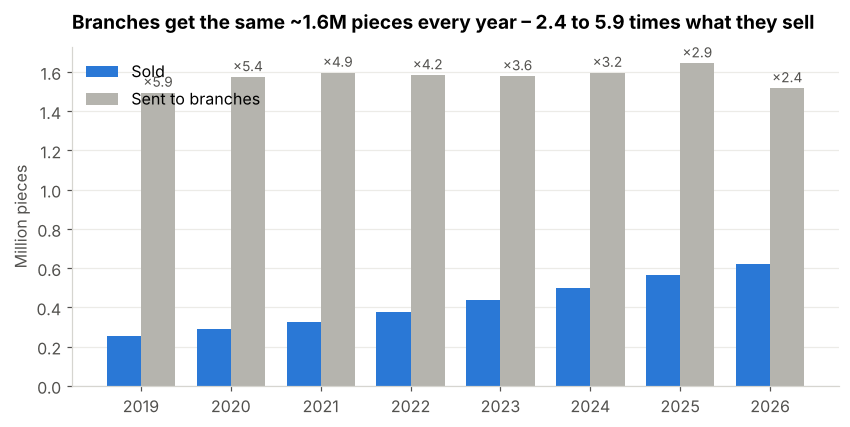

,sold,sent_to_branches,transfers,transport_cost_EGP,sent_per_sold
fy,,,,,
2019,253025,1494946,4283,3352730,5.91
2020,289688,1574346,4526,3608250,5.43
2021,325375,1596820,4628,3668990,4.91
2022,375763,1583919,4558,3648245,4.22
2023,436420,1578945,4573,3601315,3.62
2024,500525,1596263,4603,3623680,3.19
2025,567644,1644602,4705,3779600,2.90
2026,620701,1517691,4379,3446525,2.45


In [2]:
li, ti, tr = full_years(files['lines']), full_years(files['transfer_lines']), full_years(files['transfers'])
y = pd.DataFrame({'sold': li.groupby('fy').quantity.sum(), 'sent_to_branches': ti.groupby('fy').quantity_units.sum(),
                  'transfers': tr.groupby('fy').size(), 'transport_cost_EGP': tr.groupby('fy').transport_cost_EGP.sum()})
y['sent_per_sold'] = y.sent_to_branches / y.sold
fig, ax = plt.subplots(figsize=(9, 4))
w = 0.38
ax.bar(y.index - w / 2, y.sold / 1e6, w, color=BLUE, label='Sold')
ax.bar(y.index + w / 2, y.sent_to_branches / 1e6, w, color=GREY, label='Sent to branches')
for x, r in y.iterrows():
    ax.text(x + w / 2, r.sent_to_branches / 1e6 + 0.03, f'×{r.sent_per_sold:.1f}', ha='center', fontsize=9, color=INK)
ax.legend(frameon=False, loc='upper left'); ax.set_xticks(y.index)
style(ax, 'Branches get the same ~1.6M pieces every year – 2.4 to 5.9 times what they sell', 'Million pieces')
save(fig, 'c05_sent_vs_sold')
y.round(2)

correlation per SKU   (sent vs sold): 0.023
correlation per branch (sent vs sold): -0.025


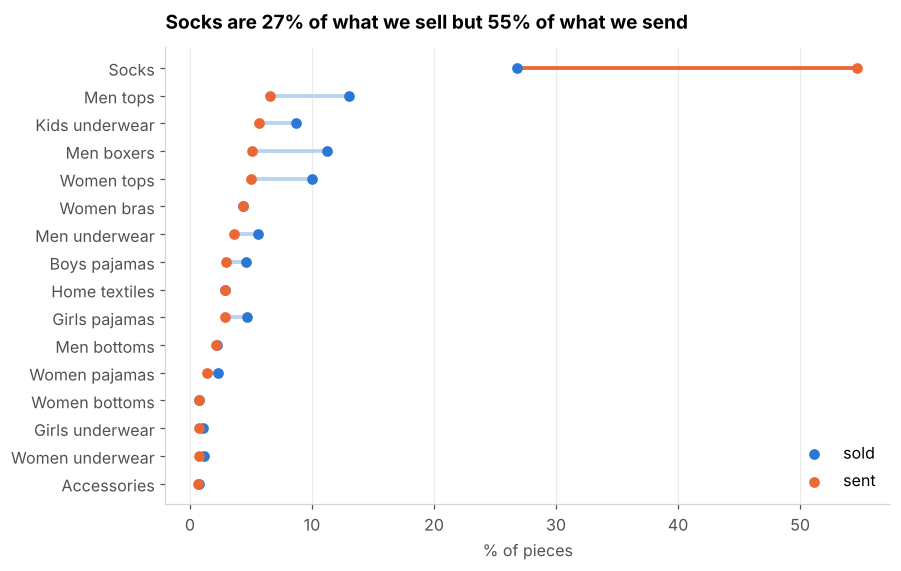

,% of pieces sold,% of pieces sent
category_en,,
Socks,26.8,54.7
Men tops,13.0,6.5
Kids underwear,8.7,5.6
Men boxers,11.2,5.1
Women tops,10.0,5.0


In [3]:
mix = pd.DataFrame({'% of pieces sold': li.groupby('category_en').quantity.sum() / li.quantity.sum() * 100,
                    '% of pieces sent': ti.groupby('category_en').quantity_units.sum() / ti.quantity_units.sum() * 100}).sort_values('% of pieces sent')
fig, ax = plt.subplots(figsize=(8.5, 5.4))
for i, (cat, r) in enumerate(mix.iterrows()):
    color = ORANGE if cat == 'Socks' else LIGHT
    ax.plot([r['% of pieces sold'], r['% of pieces sent']], [i, i], color=color, lw=2.5, zorder=1)
ax.scatter(mix['% of pieces sold'], range(len(mix)), color=BLUE, zorder=2, label='sold')
ax.scatter(mix['% of pieces sent'], range(len(mix)), color=ORANGE, zorder=2, label='sent')
ax.set_yticks(range(len(mix))); ax.set_yticklabels(mix.index); ax.legend(frameon=False, loc='lower right')
style(ax, f'Socks are {mix.loc["Socks", "% of pieces sold"]:.0f}% of what we sell but {mix.loc["Socks", "% of pieces sent"]:.0f}% of what we send')
ax.grid(axis='x', color='#ecebe7'); ax.grid(axis='y', visible=False); ax.set_xlabel('% of pieces')
save(fig, 'c05_category_mix')
sold_b = li.groupby('branch_id').quantity.sum(); got_b = ti.groupby('destination_branch_id').quantity_units.sum()
print('correlation per SKU   (sent vs sold):', round(li.groupby('sku_id').quantity.sum().corr(ti.groupby('sku_id').quantity_units.sum()), 3))
print('correlation per branch (sent vs sold):', round(sold_b.corr(got_b), 3))
mix.round(1).sort_values('% of pieces sent', ascending=False).head(5)

In [4]:
src = ti.groupby('warehouse_kind').quantity_units.sum() / ti.quantity_units.sum() * 100
print('warehouses each branch receives from:', tr.groupby('destination_branch_id').source_warehouse_id.nunique().agg(['min', 'max']).to_dict(), 'of 12')
print('transport cost: only', tr.transport_cost_EGP.nunique(), 'different values:', sorted(tr.transport_cost_EGP.unique().tolist()))
src.round(1).sort_values(ascending=False).to_frame('% of pieces sent to branches')

warehouses each branch receives from: {'min': 12, 'max': 12} of 12
transport cost: only 7 different values: [95, 155, 280, 450, 800, 1200, 2500]


,% of pieces sent to branches
warehouse_kind,
Regional DC,66.6
Returns,8.7
Finished goods,8.5
Raw materials,8.2
Central DC,8.0


17% of the pieces sent to branches leave from the **raw-materials** and **returns** warehouses, and every branch receives from **all 12** warehouses (not the nearest).

stock now: 1,814,839 pieces (346.0M EGP) = 35 months of sales
stockout_risk_score ↔ stock units correlation: 0.003


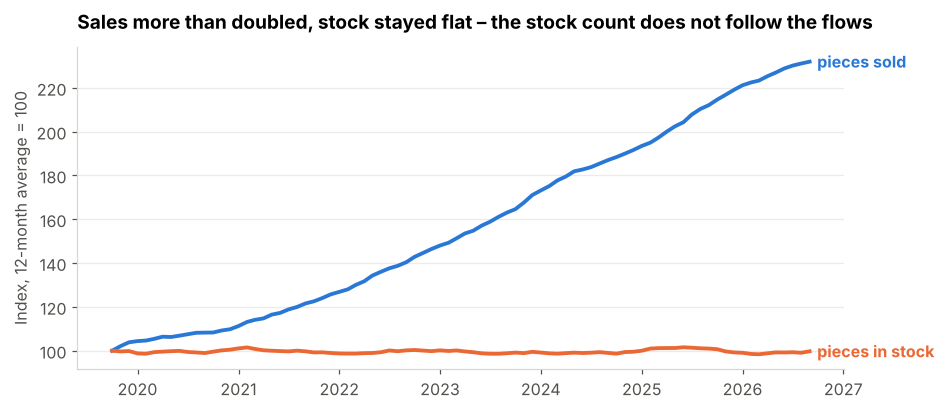

In [5]:
ms = files['stock']
stock_m = ms.groupby('month').closing_units.sum()
sales_m = files['lines'].groupby('month').quantity.sum()
both = pd.DataFrame({'stock': stock_m, 'sales': sales_m}).dropna()
both = both[(both.index >= '2018-11-01') & (both.index <= '2026-09-01')]
roll = both.rolling(12).mean().dropna()
idx = roll / roll.iloc[0] * 100
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(idx.index, idx.sales, color=BLUE, lw=2.5); ax.plot(idx.index, idx.stock, color=ORANGE, lw=2.5)
ax.text(idx.index[-1], idx.sales.iloc[-1], '  pieces sold', color=BLUE, va='center', fontweight='bold')
ax.text(idx.index[-1], idx.stock.iloc[-1], '  pieces in stock', color=ORANGE, va='center', fontweight='bold')
style(ax, 'Sales more than doubled, stock stayed flat – the stock count does not follow the flows', 'Index, 12-month average = 100')
save(fig, 'c05_stock_flat')
last = ms[ms.month == ms.month.max()]
cover = last.closing_units.sum() / (li[li.fy == 2026].quantity.sum() / 12)
print(f'stock now: {last.closing_units.sum():,} pieces ({M(last.closing_stock_value_EGP.sum())} EGP) = {cover:.0f} months of sales')
print('stockout_risk_score ↔ stock units correlation:', round(ms[['stockout_risk_score', 'closing_units']].corr().iloc[0, 1], 3))

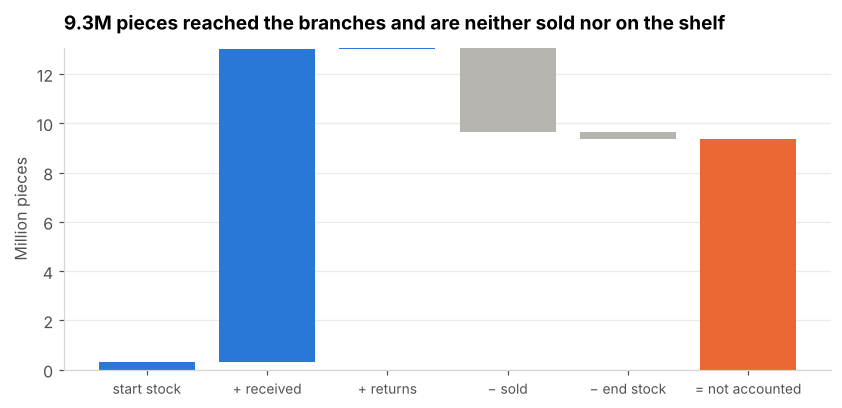

,start stock,+ received,+ returns,− sold,− end stock
pieces,325457,12677158,57136,-3398655,-315812


In [6]:
# do the branch numbers add up?  start stock + received − sold = end stock ?
bs = ms[ms.stock_location_type == 'Branch']
start, end = bs[bs.month == bs.month.min()].closing_units.sum(), bs[bs.month == bs.month.max()].closing_units.sum()
received = files['transfer_lines'].quantity_units.sum()
sold = files['lines'].quantity.sum()
returned = files['returns'].return_quantity.sum()
gap = start + received + returned - sold - end
steps = pd.Series({'start stock': start, '+ received': received, '+ returns': returned, '− sold': -sold, '− end stock': -end})
fig, ax = plt.subplots(figsize=(9, 3.8))
run = 0
for i, (k, v) in enumerate(steps.items()):
    ax.bar(i, v / 1e6, bottom=run / 1e6 if i else 0, color=BLUE if v > 0 else GREY)
    run += v
ax.bar(len(steps), gap / 1e6, color=ORANGE)
ax.set_xticks(range(len(steps) + 1)); ax.set_xticklabels(list(steps.index) + ['= not accounted'], fontsize=9)
style(ax, f'{gap / 1e6:.1f}M pieces reached the branches and are neither sold nor on the shelf', 'Million pieces')
save(fig, 'c05_unaccounted')
steps.to_frame('pieces').T

Either the transfers are recorded wrongly, or the stock counts are, or pieces are lost (shrinkage). Each case needs a different fix,
so the first step is a **physical stock count** in a sample of branches. This is the *Loss Prevention* idea from the HVIA list – and it is the biggest gap in the data.

## Demand-based allocation (simple rule – the AI version is in notebook 12)
Send each branch what it sold last year per category + 10% safety, instead of a fixed quantity.

In [7]:
need = li[li.fy == 2026].groupby(['branch_id', 'category_en']).quantity.sum() * 1.10
sent26 = ti[ti.fy == 2026].quantity_units.sum()
pieces_per_transfer = ti[ti.fy == 2026].quantity_units.sum() / tr[tr.fy == 2026].shape[0]
cost_per_transfer = tr[tr.fy == 2026].transport_cost_EGP.mean()
new_transfers = need.sum() / pieces_per_transfer
plan = pd.Series({'pieces sent FY2026': sent26, 'pieces needed (sales + 10%)': round(need.sum()),
                  'cut %': round((1 - need.sum() / sent26) * 100, 1),
                  'transfers FY2026': tr[tr.fy == 2026].shape[0], 'transfers needed': round(new_transfers),
                  'transport saved / year (EGP)': round((tr[tr.fy == 2026].shape[0] - new_transfers) * cost_per_transfer)})
plan.to_frame('value')

,value
pieces sent FY2026,1517691.0
pieces needed (sales + 10%),682771.0
cut %,55.0
transfers FY2026,4379.0
transfers needed,1970.0
transport saved / year (EGP),1896020.0


### Takeaway (card 05)
- Branches receive a **fixed ~1.6M pieces a year** (×2.4 of sales in FY2026), with the wrong mix: **socks 55% of shipments vs 27% of sales**.
- Shipments do not follow sales per SKU (0.02) or per branch (−0.03). 17% leave from raw-material / returns warehouses; every branch is served by all 12 warehouses.
- **~9M pieces are not accounted for** (sent − sold − on shelf) → stock count + transfer audit before anything else.
- Fix: allocate by demand (sales + safety): **−55% pieces moved, ~1.9M EGP transport saved per year**, and stock that matches what each branch sells.